In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv('/content/seattle-weather.csv')

In [13]:
df.head()

,precipitation,temp_max,temp_min,wind,weather
0,0.0,12.8,5.0,4.7,drizzle
1,10.9,10.6,2.8,4.5,rain
2,0.8,11.7,7.2,2.3,rain
3,20.3,12.2,5.6,4.7,rain
4,1.3,8.9,2.8,6.1,rain


In [12]:

# Drop the original 'Date' column
df = df.drop('date', axis=1)

In [14]:

le = LabelEncoder()
df['weather_encoded'] = le.fit_transform(df['weather'])

# Drop the original 'weather' column as it's now encoded
df = df.drop('weather', axis=1)

# Display the first few rows of the preprocessed data and its info
display(df.head())
display(df.info())

,precipitation,temp_max,temp_min,wind,weather_encoded
0,0.0,12.8,5.0,4.7,0
1,10.9,10.6,2.8,4.5,2
2,0.8,11.7,7.2,2.3,2
3,20.3,12.2,5.6,4.7,2
4,1.3,8.9,2.8,6.1,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   precipitation    1461 non-null   float64
 1   temp_max         1461 non-null   float64
 2   temp_min         1461 non-null   float64
 3   wind             1461 non-null   float64
 4   weather_encoded  1461 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 57.2 KB


None

Now that the data is prepared, we'll define our features (X) and target (y) and split the data into training and testing sets. Then, we'll train a Decision Tree Classifier.

In [15]:
# Define features (X) and target (y)
X = df.drop('weather_encoded', axis=1)
y = df['weather_encoded']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {len(X_train)} samples")
print(f"Test set size: {len(X_test)} samples")

Training set size: 1168 samples
Test set size: 293 samples


In [16]:
# Initialize and train the Decision Tree Classifier with max_depth=1 for a simple tree
decision_tree = DecisionTreeClassifier(random_state=42, max_depth=1)
decision_tree.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully with max_depth=1!")

Decision Tree Classifier trained successfully!


With the model trained, let's evaluate its performance on the test set.

In [17]:
# Make predictions on the test set with the simplified model
y_pred = decision_tree.predict(X_test)

# Evaluate the simplified model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy for simplified tree: {accuracy:.2f}")

print("\nClassification Report for simplified tree:")
print(classification_report(y_test, y_pred))

Accuracy: 0.73

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         9
           1       0.23      0.20      0.21        25
           2       0.90      0.88      0.89       120
           3       0.36      0.50      0.42         8
           4       0.78      0.76      0.77       131

    accuracy                           0.73       293
   macro avg       0.45      0.47      0.46       293
weighted avg       0.74      0.73      0.74       293



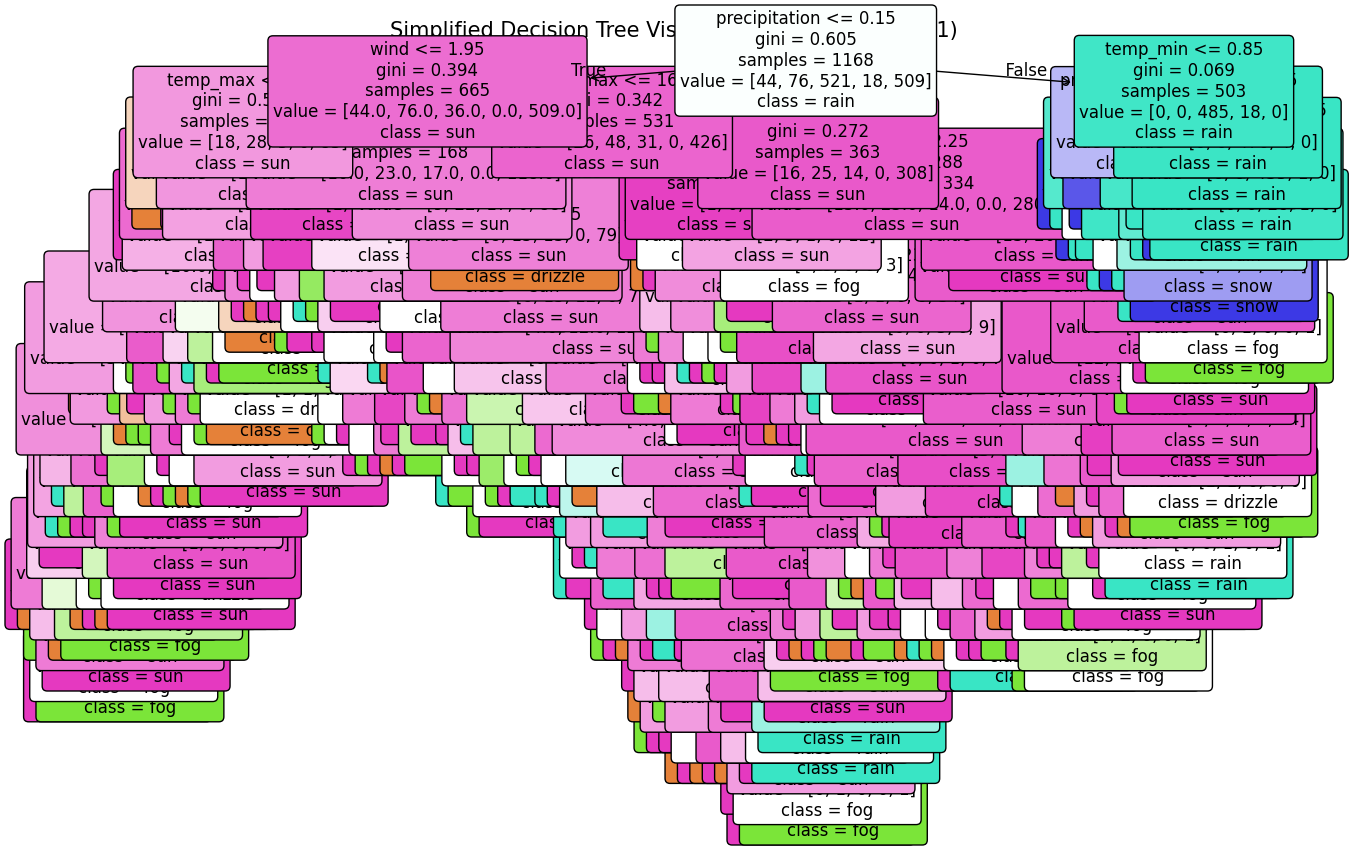

In [19]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Get feature names from the DataFrame's columns
feature_names = X.columns.tolist()

# Get class names by inverting the label encoder mapping
class_names = le.inverse_transform(sorted(y.unique()))

plt.figure(figsize=(15, 10)) # Adjust figure size for better visualization of a small tree
plot_tree(decision_tree,
          feature_names=feature_names,
          class_names=class_names,
          filled=True,
          rounded=True,
          fontsize=12)
plt.title('Simplified Decision Tree Visualization (Max Depth = 1)', fontsize=15)
plt.show()